# Data Engineering & Visualization - Milestone 1
## Member 3 - Data Integration: Housing (H5) x Transportation (T4)

**Course:** Data Engineering and Visualization, Winter 2026 - GIU
**Team member:** Member 3 (Aya Sweed) - Data integration
**Output of this notebook:** `data/clean/integrated_dataset.csv`: one row per **ZIP code x year (2022-2025)** combining construction activity (Member 1) and serious crashes (Member 2), ready for analysis (Member 4) and the website (Member 5).

**Contents**
1. Inputs, outputs and goal
2. Choosing the integration level (why ZIP code x year)
3. Loading both cleaned files and checking the join keys
4. Merging the datasets (outer join) and reporting the match
5. Post-integration cleaning
6. Derived columns
7. Validation and export
8. Research questions and visualizations (Member 3)
9. Prompts

## 1. Inputs, outputs and goal
Use the corrected housing and transportation aggregates. This is the **only notebook that writes `integrated_dataset.csv`**. Housing uses official building postcode first, with flagged nearest-crash fallback. Units are counted once per base job and attributed to first observation in the 2022-2025 window; unknown unit pairs remain unknown.

Outputs are ZIP-year records and descriptive analyses, not evidence of completed housing or causal road-safety effects. Exact row counts and reconciliation are computed below rather than assumed.

## 2. Why ZIP code x year?
Both sources have geographic identifiers and dates, but no shared individual-record ID. A record-level join would create a meaningless many-to-many product. Borough x year gives only 20 rows and conceals local variation. ZIP x year is interpretable and provides more observations while matching the available geographic quality.

A spatial join or monthly grid could be more precise only with authoritative boundaries, reliable timing and additional work. ZIP boundaries are coarse, can cross administrative boundaries, and nearest-crash fallback can be wrong. Official housing postcode is preferred. Four years are short; filing time is not construction/completion time.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "members").is_dir(), "Run from the repository root or notebooks directory."
CLEAN_DIR = ROOT / "data" / "clean"
RAW_DIR = ROOT / "data" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "members" / "member1_housing"))
sys.path.insert(0, str(ROOT / "members" / "member3_integration"))
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.max_columns", 50)

import os
HOUSING_CSV = CLEAN_DIR / "housing_clean.csv"
TRANSPORT_CSV = CLEAN_DIR / "transport_clean.csv"
OUTPUT_CSV = CLEAN_DIR / "integrated_dataset.csv"
KEYS = ["zip_code", "year"]
YEARS = [2022, 2023, 2024, 2025]
BOROUGHS = ["BRONX", "BROOKLYN", "MANHATTAN", "QUEENS", "STATEN ISLAND"]

## 3. Loading both cleaned files and checking the join keys

A merge is only correct if the keys mean exactly the same thing in both files. Before joining, we check the data contract on **both** sides:

1. `zip_code` is read as **text**, not a number. Read as a number, a ZIP like `"07001"` would lose its leading zero and could silently fail to match. Every value must be exactly 5 digits.
2. `year` is an integer in 2022-2025 in both files. A year stored as `2022.0` in one file and `2022` in the other would not match.
3. The pair (`zip_code`, `year`) is **unique** in each file. If it were not, the merge would multiply rows (one housing row x two crash rows = two output rows) and inflate every total.
4. `borough` uses the same five uppercase labels in both files, because we compare the two `borough` columns after the merge.

Each check is an `assert`, so the notebook stops immediately if a future version of an input file breaks the contract.

In [2]:
housing = pd.read_csv(HOUSING_CSV, dtype={"zip_code": str})
transport = pd.read_csv(TRANSPORT_CSV, dtype={"zip_code": str})

for name, df in [("housing", housing), ("transport", transport)]:
    print(f"{name:10s}: {df.shape[0]:,} rows x {df.shape[1]} columns, "
          f"{df['zip_code'].nunique()} ZIP codes, years {sorted(df['year'].unique().tolist())}")

print("\nHousing columns  :", list(housing.columns))
print("Transport columns:", list(transport.columns))

housing   : 877 rows x 23 columns, 221 ZIP codes, years [2022, 2023, 2024, 2025]
transport : 702 rows x 15 columns, 185 ZIP codes, years [2022, 2023, 2024, 2025]

Housing columns  : ['zip_code', 'year', 'borough', 'filing_count', 'new_construction_filings', 'permit_issued_count', 'initial_cost_total', 'initial_cost_median', 'total_floor_area', 'avg_proposed_stories', 'avg_proposed_height', 'avg_latitude', 'avg_longitude', 'outlier_filing_count', 'outlier_filing_share', 'official_zip_filings', 'approximate_zip_filings', 'unique_job_count', 'jobs_with_known_units', 'proposed_units_total', 'existing_units_total', 'net_new_units', 'is_outlier_zip_year']
Transport columns: ['zip_code', 'year', 'borough', 'crash_count', 'severe_injuries_total', 'non_severe_injuries_total', 'fatalities_total', 'fatal_crash_count', 'severe_per_crash', 'night_crash_share', 'night_crash_count', 'crashes_with_known_time', 'avg_latitude', 'avg_longitude', 'is_outlier_zip_year']


Validate key types, time coverage, uniqueness and borough labels before merging.

In [3]:
def check_keys(df, name):
    assert pd.api.types.is_string_dtype(df["zip_code"]), f"{name}: zip_code must be text"
    assert df["zip_code"].str.fullmatch(r"\d{5}").all(), f"{name}: every zip_code must be 5 digits"
    assert df["zip_code"].notna().all(), f"{name}: zip_code has missing values"
    assert pd.api.types.is_integer_dtype(df["year"]), f"{name}: year must be an integer"
    assert df["year"].isin(YEARS).all(), f"{name}: year outside 2022-2025"
    n_dup = int(df.duplicated(KEYS).sum())
    assert n_dup == 0, f"{name}: {n_dup} duplicated (zip_code, year) pairs"
    assert df["borough"].isin(BOROUGHS).all(), f"{name}: unexpected borough label"
    print(f"{name:10s}: all key checks PASSED "
          f"(5-digit text ZIPs, integer years 2022-2025, unique (zip_code, year), uppercase boroughs)")

check_keys(housing, "housing")
check_keys(transport, "transport")

# Rows per year: shows whether either file is missing a year for some ZIP codes
rows_per_year = pd.DataFrame({
    "housing": housing["year"].value_counts().sort_index(),
    "transport": transport["year"].value_counts().sort_index(),
})
rows_per_year.index.name = "year"
rows_per_year

housing   : all key checks PASSED (5-digit text ZIPs, integer years 2022-2025, unique (zip_code, year), uppercase boroughs)
transport : all key checks PASSED (5-digit text ZIPs, integer years 2022-2025, unique (zip_code, year), uppercase boroughs)


,housing,transport
year,,
2022,218,172
2023,220,174
2024,219,179
2025,220,177


List non-key columns shared by both sources so merge suffixes can be resolved explicitly.

In [4]:
# Columns present in both files (other than the keys): these will collide in the merge
shared = sorted((set(housing.columns) & set(transport.columns)) - set(KEYS))
print("Columns in both files besides the keys:", shared)

Columns in both files besides the keys: ['avg_latitude', 'avg_longitude', 'borough', 'is_outlier_zip_year']


**Result.** Both files pass every key check, so they can be merged directly on `zip_code` + `year` without any conversion.

- Neither file has a row for every ZIP code in every year (see the rows-per-year table). A housing ZIP-year is absent when no filing was assigned to it; a transport ZIP-year is absent when **no serious crash was recorded** there, because Member 2 aggregated crash records. This matters in Section 5, where we decide what a missing row means.
- Four columns besides the keys appear in **both** files: `borough`, `avg_latitude`, `avg_longitude`, and `is_outlier_zip_year`. They describe different things in each file (e.g. the centroid of construction filings vs. the centroid of crashes), so they must not be silently merged. They are resolved in Section 5.

## 4. Merging the datasets (outer join) and reporting the match

**Join type: outer.** We keep every ZIP-year that appears in *either* file.
- An **inner** join would keep only ZIP-years present in both files and silently drop the rest. Dropping a ZIP-year with construction but no serious crash would bias the data towards crash-prone places, and that is exactly the relationship we want to study.
- An outer join keeps those rows and lets us decide openly, in Section 5, how to fill the gaps.

`indicator=True` adds a `_merge` column telling us where each row came from (`both`, `left_only` = housing only, `right_only` = transport only). Columns that exist in both files get the suffixes `_housing` / `_transport` so nothing is overwritten.

`validate="one_to_one"` makes pandas raise an error if a key were duplicated in either file, a second guard on top of the checks in Section 3.

In [5]:
merged = pd.merge(
    housing, transport,
    on=KEYS, how="outer",
    suffixes=("_housing", "_transport"),
    indicator=True, validate="one_to_one",
)
merged["match_status"] = merged["_merge"].map({
    "both": "In both files",
    "left_only": "Housing only",
    "right_only": "Transport only",
})
merged = merged.drop(columns="_merge")

print(f"housing rows   : {len(housing):,}")
print(f"transport rows : {len(transport):,}")
print(f"merged rows    : {len(merged):,}  ({merged['zip_code'].nunique()} ZIP codes)\n")
match_counts = merged["match_status"].value_counts().reindex(["In both files", "Housing only", "Transport only"])
print(match_counts.to_string())

# Sanity check: outer join row count = both + housing only + transport only
assert len(merged) == len(housing) + len(transport) - match_counts["In both files"]

housing rows   : 877
transport rows : 702
merged rows    : 881  (222 ZIP codes)

match_status
In both files     698
Housing only      179
Transport only      4


The left panel gives the overall match. The right panel shows only the one-sided rows per year, because the matched bars would hide them. If the one-sided rows were concentrated in a single year, that would point to a coverage gap in one source rather than to geography.

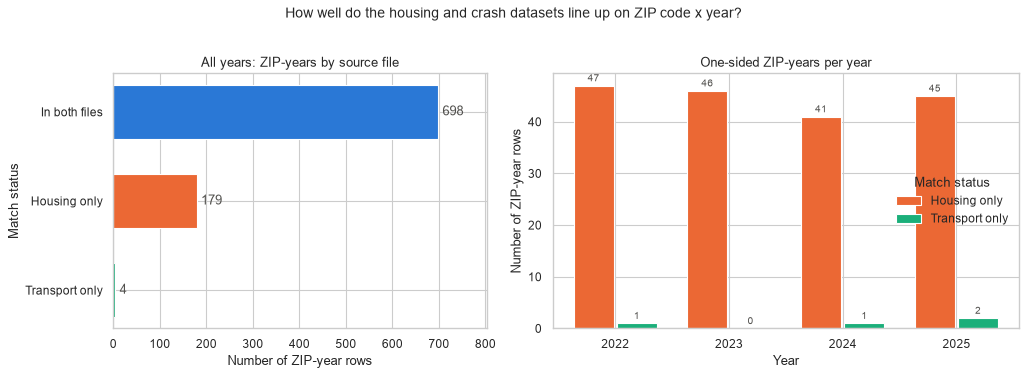

match_status,In both files,Housing only,Transport only
year,,,
2022,171,47,1
2023,174,46,0
2024,178,41,1
2025,175,45,2


In [6]:
# Chart: how well do the two files line up?
STATUS_ORDER = ["In both files", "Housing only", "Transport only"]
STATUS_COLORS = {"In both files": "#2a78d6", "Housing only": "#eb6834", "Transport only": "#1baf7a"}

by_year = (merged.groupby(["year", "match_status"]).size()
           .unstack(fill_value=0).reindex(columns=STATUS_ORDER, fill_value=0))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})

# Left: overall counts
ax = axes[0]
bars = ax.barh(STATUS_ORDER[::-1], match_counts[STATUS_ORDER[::-1]],
               color=[STATUS_COLORS[s] for s in STATUS_ORDER[::-1]], height=0.6)
ax.bar_label(bars, labels=[f"{v:,}" for v in match_counts[STATUS_ORDER[::-1]]], padding=4, color="#52514e")
ax.set_title("All years: ZIP-years by source file")
ax.set_xlabel("Number of ZIP-year rows")
ax.set_ylabel("Match status")
ax.set_xlim(0, match_counts.max() * 1.15)

# Right: the one-sided rows per year (the 'both' bars would dwarf them)
ax = axes[1]
x = np.arange(len(YEARS))
w = 0.38
for i, status in enumerate(["Housing only", "Transport only"]):
    b = ax.bar(x + (i - 0.5) * w, by_year[status].reindex(YEARS, fill_value=0), width=w - 0.03,
               color=STATUS_COLORS[status], label=status)
    ax.bar_label(b, padding=2, color="#52514e", fontsize=9)
ax.set_xticks(x, YEARS)
ax.set_title("One-sided ZIP-years per year")
ax.set_xlabel("Year")
ax.set_ylabel("Number of ZIP-year rows")
ax.legend(title="Match status", frameon=False)

fig.suptitle("How well do the housing and crash datasets line up on ZIP code x year?", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

by_year

Next we list the one-sided ZIP codes and check whether each one is one-sided in **every** year (a ZIP that one source never covers) or only in **some** years (a ZIP-year that simply had no recorded event).

In [7]:
# Which ZIP codes are one-sided, and are they one-sided in every year or only some?
housing_zips, transport_zips = set(housing["zip_code"]), set(transport["zip_code"])
print("ZIP codes only in housing  :", sorted(housing_zips - transport_zips) or "none")
print("ZIP codes only in transport:", sorted(transport_zips - housing_zips) or "none")

one_sided = merged[merged["match_status"] != "In both files"]
summary = (one_sided.groupby(["match_status", "zip_code"])
           .agg(borough=("borough_housing", "first"), years=("year", lambda s: sorted(s.tolist())),
                filing_count=("filing_count", "sum"))
           .reset_index())
summary["borough"] = summary["borough"].fillna(
    summary["zip_code"].map(transport.drop_duplicates("zip_code").set_index("zip_code")["borough"]))
summary

ZIP codes only in housing  : ['10041', '10044', '10055', '10103', '10104', '10105', '10106', '10107', '10110', '10112', '10115', '10118', '10119', '10120', '10121', '10122', '10123', '10151', '10153', '10155', '10158', '10162', '10169', '10171', '10173', '10174', '10175', '10176', '10177', '10178', '10271', '10303', '11005', '11021', '11109', '11359', '11697']
ZIP codes only in transport: ['10111']


,match_status,zip_code,borough,years,filing_count
0,Housing only,10004,MANHATTAN,"[2022, 2023]",877.0
1,Housing only,10005,MANHATTAN,[2025],721.0
2,Housing only,10006,MANHATTAN,"[2022, 2025]",509.0
3,Housing only,10020,MANHATTAN,"[2022, 2023, 2025]",1381.0
4,Housing only,10041,MANHATTAN,"[2022, 2023, 2024, 2025]",140.0
5,Housing only,10044,MANHATTAN,"[2022, 2023, 2024, 2025]",387.0
6,Housing only,10055,MANHATTAN,"[2022, 2023, 2024, 2025]",148.0
7,Housing only,10103,MANHATTAN,"[2022, 2023, 2024, 2025]",251.0
8,Housing only,10104,MANHATTAN,"[2022, 2023, 2024, 2025]",282.0
9,Housing only,10105,MANHATTAN,"[2022, 2023, 2024, 2025]",257.0


### Reading the join audit
Most one-sided rows are **housing only**. The ZIP codes that are housing-only in *every* year are mostly Midtown and Financial District ZIPs assigned to a single large building or complex (for example 10118), plus a few small or edge ZIPs. Official building postcode puts filings in these ZIPs, but a crash on the street outside is recorded under the surrounding street ZIP, so the crash file can never contain them. For these ZIPs a recorded crash count of 0 comes from how ZIP codes are assigned, not from safe streets.

They stay in the integrated file, because their filings are real. Section 8 excludes ZIP codes that never appear in the crash file from the research questions, so they do not add artificial zero-crash points.

Transport-only rows mean housing coverage is unknown, not proof of no development.

## 5. Post-integration cleaning

Merging creates problems that did not exist in either input file. We fix four kinds:

1. **Duplicated columns**: `borough`, `avg_latitude`, `avg_longitude` and `is_outlier_zip_year` now exist twice (`_housing` / `_transport`).
2. **New missing values** created by the outer join: crash columns are empty on the housing-only rows, and housing columns are empty on the transport-only rows (counts in Section 4).
3. **Source flags**: after filling, we must still be able to tell a real value from a filled one.
4. **Data types**: integer count columns became decimals during the merge, because pandas stores missing numbers as `NaN`, which is a float.

We first record the missing values right after the merge, so we can show a before/after table at the end of this section.

In [8]:
integrated = merged.copy()
missing_before = integrated.isna().sum()
print("Columns with missing values right after the merge:")
print(missing_before[missing_before > 0].to_string())

Columns with missing values right after the merge:
borough_housing                    4
filing_count                       4
new_construction_filings           4
permit_issued_count                4
initial_cost_total                 4
initial_cost_median                4
total_floor_area                   6
avg_proposed_stories              12
avg_proposed_height               13
avg_latitude_housing               8
avg_longitude_housing              8
outlier_filing_count               4
outlier_filing_share               4
official_zip_filings               4
approximate_zip_filings            4
unique_job_count                   4
jobs_with_known_units              4
proposed_units_total               5
existing_units_total               5
net_new_units                      5
is_outlier_zip_year_housing        4
borough_transport                179
crash_count                      179
severe_injuries_total            179
non_severe_injuries_total        179
fatalities_total        

### 5.1 Duplicated columns

**`borough`.** We compare the two versions wherever both exist. If they disagreed, the same ZIP code would sit in two boroughs, which would point to a ZIP-assignment error. Then we keep one column, taking the housing value and filling from transport where housing is missing (the transport-only rows).

In [9]:
both_present = integrated["borough_housing"].notna() & integrated["borough_transport"].notna()
conflicts = integrated[both_present & (integrated["borough_housing"] != integrated["borough_transport"])]
print(f"Rows where both files give a borough: {both_present.sum()}")
print(f"Rows where they disagree           : {len(conflicts)}")

assert conflicts.empty, "Resolve source borough conflicts before export."

integrated["borough"] = integrated["borough_housing"].fillna(integrated["borough_transport"])
assert integrated["borough"].isin(BOROUGHS).all()

# A ZIP code must belong to exactly one borough across all years
assert (integrated.groupby("zip_code")["borough"].nunique() == 1).all(), "Resolve ZIP/borough ambiguity before export"
print("Every ZIP code maps to exactly one borough.")

Rows where both files give a borough: 698
Rows where they disagree           : 0
Every ZIP code maps to exactly one borough.


**`avg_latitude` / `avg_longitude`.** These mean different things: the housing pair is the centre of that year's *construction filings*, while the transport pair is the centre of that year's *crashes*. They also move from year to year with wherever activity happened. Keeping four coordinate columns would confuse the people using the file. They are only needed to place a ZIP code on a map (Members 4 and 5), so we replace them with **one fixed point per ZIP code**: `zip_latitude` / `zip_longitude`, the mean of all available housing and crash centroids for that ZIP across all years. This also gives a location to rows where one side is missing. We first measure how far apart the two centres are, to show that averaging them is reasonable.

In [10]:
lat_cols = ["avg_latitude_housing", "avg_latitude_transport"]
lon_cols = ["avg_longitude_housing", "avg_longitude_transport"]

# Distance between filing centre and crash centre in the same ZIP-year (1 degree of latitude ~ 111 km)
dist_km = np.hypot(
    integrated["avg_latitude_housing"] - integrated["avg_latitude_transport"],
    (integrated["avg_longitude_housing"] - integrated["avg_longitude_transport"]) * np.cos(np.radians(40.7)),
) * 111
print(f"Filing centre vs crash centre, same ZIP-year: median {dist_km.median():.2f} km, "
      f"90th percentile {dist_km.quantile(0.9):.2f} km, max {dist_km.max():.2f} km")

long_coords = pd.concat([
    integrated[["zip_code", "avg_latitude_housing", "avg_longitude_housing"]].set_axis(["zip_code", "lat", "lon"], axis=1),
    integrated[["zip_code", "avg_latitude_transport", "avg_longitude_transport"]].set_axis(["zip_code", "lat", "lon"], axis=1),
])
zip_centroids = (long_coords.groupby("zip_code")[["lat", "lon"]].mean().round(6)
                 .rename(columns={"lat": "zip_latitude", "lon": "zip_longitude"}))
integrated = integrated.merge(zip_centroids, on="zip_code", how="left")
assert integrated["zip_latitude"].isna().equals(integrated["zip_longitude"].isna())
missing_map_zips = sorted(integrated.loc[integrated["zip_latitude"].isna(), "zip_code"].unique())
print(f"Descriptive map points for {len(zip_centroids) - len(missing_map_zips)} of {len(zip_centroids)} ZIPs.")
print(f"ZIPs without any source coordinates (retained for non-map analysis): {missing_map_zips}")


Filing centre vs crash centre, same ZIP-year: median 0.27 km, 90th percentile 0.66 km, max 4.50 km
Descriptive map points for 221 of 222 ZIPs.
ZIPs without any source coordinates (retained for non-map analysis): ['10044']


**`is_outlier_zip_year`.** The two flags answer different questions: *unusually many filings* (housing) vs *unusually many crashes* (transport). Both are useful, so we keep both under clear names: `is_outlier_housing` and `is_outlier_transport`. Where a side has no data, there is nothing to be an outlier, so the flag is `False`; the source flags added in 5.3 show that case explicitly.

In [11]:
integrated["is_outlier_housing"] = integrated["is_outlier_zip_year_housing"].fillna(False).astype(bool)
integrated["is_outlier_transport"] = integrated["is_outlier_zip_year_transport"].fillna(False).astype(bool)

integrated = integrated.drop(columns=[
    "borough_housing", "borough_transport",
    "avg_latitude_housing", "avg_latitude_transport", "avg_longitude_housing", "avg_longitude_transport",
    "is_outlier_zip_year_housing", "is_outlier_zip_year_transport",
])
print(integrated["is_outlier_housing"].sum(), "housing outlier rows;",
      integrated["is_outlier_transport"].sum(), "transport outlier rows")

47 housing outlier rows; 4 transport outlier rows


### 5.2 Missing values: structural absence versus unknown measurements
An outer join keeps every source key. A housing-only ZIP-year is assigned zero **recorded** serious crashes under the assumption that the retained crash table has no record there; this is not proof of no crashes outside SIRTA or among excluded rows. Preserve the source flags.

A transport-only row has unknown housing coverage and **must not** be filled with zero filings. Unknown source measures remain missing. Shares are undefined when their denominator is zero. Housing unit totals can also be missing where first-observed jobs have no complete unit pairs; `jobs_with_known_units` exposes partial reporting.

In [12]:
CRASH_COUNTS = ["crash_count", "severe_injuries_total", "non_severe_injuries_total",
                "fatalities_total", "fatal_crash_count", "night_crash_count", "crashes_with_known_time"]
CRASH_RATES = ["severe_per_crash", "night_crash_share"]
housing_only = integrated["match_status"] == "Housing only"
transport_only = integrated["match_status"] == "Transport only"
assert integrated.loc[~housing_only, ["crash_count", "severe_injuries_total"]].notna().all().all()
integrated.loc[housing_only, CRASH_COUNTS] = 0
print(f"Structural zero recorded-crash counts: {housing_only.sum()} housing-only rows.")
print(f"Unknown housing coverage: {transport_only.sum()} transport-only rows.")
display(integrated.isna().sum()[lambda s: s > 0].to_frame("missing"))

Structural zero recorded-crash counts: 179 housing-only rows.
Unknown housing coverage: 4 transport-only rows.


,missing
filing_count,4
new_construction_filings,4
permit_issued_count,4
initial_cost_total,4
initial_cost_median,4
total_floor_area,6
avg_proposed_stories,12
avg_proposed_height,13
outlier_filing_count,4
outlier_filing_share,4


### 5.3 Source flags

Two boolean columns record where each row's data came from, so filled values can always be told apart from observed ones:
- `has_housing_data`: `True` if the housing file had a row for this ZIP-year (`False` on the transport-only rows).
- `has_crash_data`: `True` if the crash file had a row (`False` on the housing-only rows, whose crash counts were set to 0 in 5.2).

They replace the temporary `match_status` column.

In [13]:
integrated["has_housing_data"] = integrated["match_status"] != "Transport only"
integrated["has_crash_data"] = integrated["match_status"] != "Housing only"
integrated = integrated.drop(columns="match_status")

pd.crosstab(integrated["has_housing_data"], integrated["has_crash_data"], margins=True)

has_crash_data,False,True,All
has_housing_data,,,
False,0,4,4
True,179,698,877
All,179,702,881


### 5.4 Data types and column order
Keep text ZIPs and integer years. Nullable integer counts preserve unknown source coverage/measurements without decimal formatting. Coordinates and rates remain numeric; source flags remain boolean. The exported schema preserves provenance and job-unit/time coverage.

In [14]:
HOUSING_COUNTS = ["filing_count", "new_construction_filings", "permit_issued_count", "outlier_filing_count", "official_zip_filings", "approximate_zip_filings", "unique_job_count", "jobs_with_known_units"]
for col in HOUSING_COUNTS:
    integrated[col] = integrated[col].round().astype("Int64")
for col in CRASH_COUNTS:
    integrated[col] = integrated[col].round().astype("Int64")
integrated["zip_code"] = integrated["zip_code"].astype(str)
integrated["year"] = integrated["year"].astype(int)

REPLACED = ["borough", "avg_latitude", "avg_longitude", "is_outlier_zip_year"]
HOUSING_COLS = [c for c in housing.columns if c not in KEYS + REPLACED]
TRANSPORT_COLS = [c for c in transport.columns if c not in KEYS + REPLACED]
ORDER = (KEYS + ["borough", "zip_latitude", "zip_longitude", "has_housing_data", "has_crash_data"]
         + HOUSING_COLS + TRANSPORT_COLS + ["is_outlier_housing", "is_outlier_transport"])
assert set(ORDER) == set(integrated.columns), set(integrated.columns) ^ set(ORDER)
integrated = integrated[ORDER].sort_values(KEYS).reset_index(drop=True)

integrated.dtypes.to_frame("dtype").T

,zip_code,year,borough,zip_latitude,zip_longitude,has_housing_data,has_crash_data,filing_count,new_construction_filings,permit_issued_count,initial_cost_total,initial_cost_median,total_floor_area,avg_proposed_stories,avg_proposed_height,outlier_filing_count,outlier_filing_share,official_zip_filings,approximate_zip_filings,unique_job_count,jobs_with_known_units,proposed_units_total,existing_units_total,net_new_units,crash_count,severe_injuries_total,non_severe_injuries_total,fatalities_total,fatal_crash_count,severe_per_crash,night_crash_share,night_crash_count,crashes_with_known_time,is_outlier_housing,is_outlier_transport
dtype,str,int64,str,float64,float64,bool,bool,Int64,Int64,Int64,float64,float64,float64,float64,float64,Int64,float64,Int64,Int64,Int64,Int64,float64,float64,float64,Int64,Int64,Int64,Int64,Int64,float64,float64,Int64,Int64,bool,bool


### 5.5 Before/after missing values
The table below distinguishes resolved merge gaps from source/reporting gaps. Unknown housing measures, incomplete job unit pairs and undefined rates stay missing. Do not replace all blanks with zero.

In [15]:
missing_after = integrated.isna().sum()
mv = pd.DataFrame({
    "missing_after_merge": missing_before.reindex(integrated.columns).fillna(0),
    "missing_after_cleaning": missing_after,
}).astype(int)
mv = mv[(mv > 0).any(axis=1)]
mv["explanation"] = [
    "Undefined without known-time crashes" if c == "night_crash_share" else
    "Undefined without recorded crashes" if c == "severe_per_crash" else
    "Unknown source measurements, incomplete unit pairs, or no housing coverage; not imputed"
    for c in mv.index
]
display(mv)

,missing_after_merge,missing_after_cleaning,explanation
zip_latitude,0,4,"Unknown source measurements, incomplete unit p..."
zip_longitude,0,4,"Unknown source measurements, incomplete unit p..."
filing_count,4,4,"Unknown source measurements, incomplete unit p..."
new_construction_filings,4,4,"Unknown source measurements, incomplete unit p..."
permit_issued_count,4,4,"Unknown source measurements, incomplete unit p..."
initial_cost_total,4,4,"Unknown source measurements, incomplete unit p..."
initial_cost_median,4,4,"Unknown source measurements, incomplete unit p..."
total_floor_area,6,6,"Unknown source measurements, incomplete unit p..."
avg_proposed_stories,12,12,"Unknown source measurements, incomplete unit p..."
avg_proposed_height,13,13,"Unknown source measurements, incomplete unit p..."


**Result.** After cleaning, the integrated table has one `borough` (no conflicts between the files), one fixed map position per ZIP code, two clearly named outlier flags, and two source flags. Every remaining missing value has a stated reason:
- **Housing columns** are missing on the transport-only rows (`has_housing_data = False`). Unit totals are also missing where no first-observed job reported a complete unit pair.
- **Crash rates** (`severe_per_crash`, `night_crash_share`) are missing on the housing-only rows, where there is no crash to divide by.
- **Average stories/height and floor area** are missing where no filing reported them.
- **Map points** are missing only for ZIP codes with no source coordinates at all.

Nothing was filled with a number we cannot defend.

## 6. Derived measures
- Serious crashes per 100 filings: descriptive ratio between unrelated event types, **not personal risk**. Zero/missing filings produce missing ratios.
- Year-over-year differences: match the same ZIP to the actual preceding calendar year, not previous row order.
- Next-year crashes: match the same ZIP to year + 1; the final year is missing by definition.
- Severe injuries per 1,000 reported proposed units: denominator counts once per first-observed job with a complete unit pair. This is **not injuries per resident or per newly built home** and may be distorted by reporting coverage. It is also unstable where very few units are proposed (1 severe injury over 1 proposed unit scores 1,000), so read it next to `proposed_units_total`.

The corrected unit accounting removes amendment duplication, but does not make the reported units a completion measure.

In [16]:
# 1. Rate: serious crashes per 100 construction filings (Int64 -> float so missing stays NaN)
filings = integrated["filing_count"].astype("float").where(integrated["filing_count"] > 0)
integrated["crashes_per_100_filings"] = (integrated["crash_count"] / filings * 100).round(2)

# 2-3. Year-over-year change, matched on year - 1 (not on row position)
prev = integrated[KEYS + ["filing_count", "crash_count"]].copy()
prev["year"] = prev["year"] + 1                      # last year's values, labelled with this year
prev = prev.rename(columns={"filing_count": "filing_prev", "crash_count": "crash_prev"})
integrated = integrated.merge(prev, on=KEYS, how="left")
integrated["filing_change_yoy"] = (integrated["filing_count"].astype("float") - integrated["filing_prev"].astype("float"))
integrated["crash_change_yoy"] = integrated["crash_count"] - integrated["crash_prev"]

# 4. Next year's crashes, matched on year + 1
nxt = integrated[KEYS + ["crash_count"]].copy()
nxt["year"] = nxt["year"] - 1                        # next year's values, labelled with this year
nxt = nxt.rename(columns={"crash_count": "crashes_next_year"})
integrated = integrated.merge(nxt, on=KEYS, how="left").drop(columns=["filing_prev", "crash_prev"])

# 5. Descriptive only: severe injuries per 1,000 proposed dwelling units (0 units -> undefined)
units = integrated["proposed_units_total"].where(integrated["proposed_units_total"] > 0)
integrated["severe_injuries_per_1000_units"] = (integrated["severe_injuries_total"] / units * 1000).round(3)

# Whole-number columns keep a nullable integer type
for col in ["filing_change_yoy", "crash_change_yoy", "crashes_next_year"]:
    integrated[col] = integrated[col].round().astype("Int64")

DERIVED = ["crashes_per_100_filings", "filing_change_yoy", "crash_change_yoy",
           "crashes_next_year", "severe_injuries_per_1000_units"]
integrated[DERIVED].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
crashes_per_100_filings,877.0,1.89,2.1,0.0,0.5,1.49,2.74,33.33
filing_change_yoy,655.0,26.13,96.87,-491.0,-23.0,11.0,64.0,435.0
crash_change_yoy,657.0,0.36,5.36,-20.0,-2.0,0.0,3.0,21.0
crashes_next_year,657.0,12.23,10.95,0.0,2.0,10.0,20.0,48.0
severe_injuries_per_1000_units,747.0,9.76,45.02,0.0,0.4,1.72,5.24,1000.0


Check that each derived column is blank exactly where it should be: lag columns only where the neighbouring calendar year exists for the same ZIP, crashes per 100 filings only where filings are known, and no infinite ratios.

In [17]:
previous_keys = set(zip(integrated["zip_code"], integrated["year"]))
has_previous = pd.Series([(z, y - 1) in previous_keys for z, y in zip(integrated["zip_code"], integrated["year"])])
has_next = pd.Series([(z, y + 1) in previous_keys for z, y in zip(integrated["zip_code"], integrated["year"])])
assert integrated["crashes_next_year"].notna().equals(has_next)
assert integrated["crash_change_yoy"].notna().equals(has_previous)
assert integrated.loc[~integrated["has_housing_data"], "crashes_per_100_filings"].isna().all()
assert not np.isinf(integrated[DERIVED].astype(float).to_numpy()).any()
display(integrated[DERIVED].isna().sum().to_frame("missing"))

,missing
crashes_per_100_filings,4
filing_change_yoy,226
crash_change_yoy,224
crashes_next_year,224
severe_injuries_per_1000_units,134


A worked example on one ZIP code, so the lag and rate columns can be checked by hand.

In [18]:
# Example: one ZIP code over the four years, to check the derived columns by eye
integrated.loc[integrated["zip_code"] == "11207",
               KEYS + ["filing_count", "crash_count", "severe_injuries_total", "proposed_units_total"] + DERIVED]

,zip_code,year,filing_count,crash_count,severe_injuries_total,proposed_units_total,crashes_per_100_filings,filing_change_yoy,crash_change_yoy,crashes_next_year,severe_injuries_per_1000_units
533,11207,2022,1312,42,40,26534.0,3.2,<NA>,<NA>,38,1.507
534,11207,2023,1385,38,38,19562.0,2.74,73,-4,48,1.943
535,11207,2024,1500,48,46,10509.0,3.2,115,10,28,4.377
536,11207,2025,1516,28,27,8120.0,1.85,16,-20,<NA>,3.325


### Derived-column interpretation
Checks match actual neighboring calendar keys, so a missing year is not mistaken for an adjacent one. The final year's next-year crashes remain unknown. Job-unit ratios use the corrected, once-per-job reports, but still do not represent risk per resident or completed home. Inspect ZIP 11207 as a worked example.

## 7. Validate and export
Check the union of input keys, unique ZIP-years, integer years, geographic formats, source-presence flags, and reconciliation of all count/unit/cost measures. Do not hard-code a snapshot row count: public data and official ZIP coverage can change.

In [19]:
source_keys = set(map(tuple, housing[KEYS].to_numpy())) | set(map(tuple, transport[KEYS].to_numpy()))
assert set(map(tuple, integrated[KEYS].to_numpy())) == source_keys
assert len(integrated) == len(source_keys)
assert not integrated.duplicated(KEYS).any()
recon = []
for col in ["filing_count", "unique_job_count", "jobs_with_known_units", "new_construction_filings",
            "permit_issued_count", "proposed_units_total", "existing_units_total", "net_new_units",
            "official_zip_filings", "approximate_zip_filings", "initial_cost_total"]:
    recon.append((col, "housing", housing[col].sum(), integrated[col].sum()))
for col in CRASH_COUNTS:
    recon.append((col, "transport", transport[col].sum(), integrated[col].sum()))
recon = pd.DataFrame(recon, columns=["column", "source_file", "source_total", "integrated_total"])
recon["match"] = np.isclose(recon["source_total"].astype(float), recon["integrated_total"].astype(float))
assert recon["match"].all(), "Totals changed during integration."
check_keys(integrated, "integrated")
assert all(c == c.lower() and " " not in c for c in integrated.columns)
assert integrated["jobs_with_known_units"].le(integrated["unique_job_count"]).fillna(True).all()
print(f"Validated {len(integrated):,} ZIP-years, {integrated.shape[1]} columns.")
display(recon)

integrated: all key checks PASSED (5-digit text ZIPs, integer years 2022-2025, unique (zip_code, year), uppercase boroughs)
Validated 881 ZIP-years, 40 columns.


,column,source_file,source_total,integrated_total,match
0,filing_count,housing,5.979340e+05,5.979340e+05,True
1,unique_job_count,housing,3.462940e+05,3.462940e+05,True
2,jobs_with_known_units,housing,2.981760e+05,2.981760e+05,True
3,new_construction_filings,housing,4.037900e+04,4.037900e+04,True
4,permit_issued_count,housing,2.337800e+05,2.337800e+05,True
5,proposed_units_total,housing,1.263380e+07,1.263380e+07,True
6,existing_units_total,housing,1.197012e+07,1.197012e+07,True
7,net_new_units,housing,6.636820e+05,6.636820e+05,True
8,official_zip_filings,housing,5.977610e+05,5.977610e+05,True
9,approximate_zip_filings,housing,1.730000e+02,1.730000e+02,True


Describe every exported column for the analysis and website handoff.

In [20]:
# Column summary (data dictionary for Members 4 and 5)
DESCRIPTIONS = {
    "official_zip_filings": "filings assigned using official building postcode",
    "approximate_zip_filings": "filings assigned by flagged nearest-crash fallback",
    "unique_job_count": "base jobs first observed in this ZIP-year within 2022-2025",
    "jobs_with_known_units": "first-observed jobs with a complete reported unit pair",
    "night_crash_count": "known-time crashes in hours 00-05 or 22-23",
    "crashes_with_known_time": "crashes with a usable time; nighttime-share denominator",
    "zip_code": "5-digit ZIP code (text)", "year": "calendar year 2022-2025",
    "borough": "NYC borough (uppercase)",
    "zip_latitude": "descriptive map point from source means; blank when no source coordinates exist",
    "zip_longitude": "fixed map point of the ZIP (see zip_latitude)",
    "has_housing_data": "False = no housing source row; housing columns remain unknown",
    "has_crash_data": "False = no serious crash recorded; crash counts filled with 0",
    "filing_count": "construction job filings (H5) in the ZIP-year",
    "new_construction_filings": "filings labelled New Building in source job_type",
    "permit_issued_count": "filings that reached permit issued / LOC issued",
    "proposed_units_total": "reported proposed units counted once per first-observed job with complete pair",
    "existing_units_total": "reported existing units from the same complete job pairs",
    "net_new_units": "job-cohort proposed minus existing reported units; not completions",
    "initial_cost_total": "sum of declared filing costs, USD; related filings may overlap",
    "initial_cost_median": "median declared job cost, USD",
    "total_floor_area": "sum of construction floor area, sq ft",
    "avg_proposed_stories": "mean proposed stories (filings that report it)",
    "avg_proposed_height": "mean proposed height, ft (filings that report it)",
    "outlier_filing_count": "filings flagged as outliers by Member 1",
    "outlier_filing_share": "share of filings flagged as outliers",
    "crash_count": "serious-injury crashes (SIRTA, T4)",
    "severe_injuries_total": "people seriously injured",
    "non_severe_injuries_total": "people with non-serious injuries in those crashes",
    "fatalities_total": "people killed",
    "fatal_crash_count": "crashes with at least one death",
    "severe_per_crash": "serious injuries per crash (blank if 0 crashes)",
    "night_crash_share": "share of crashes at night (blank if 0 crashes)",
    "is_outlier_housing": "unusually high filing_count (Member 1's IQR flag)",
    "is_outlier_transport": "unusually high crash_count (Member 2's IQR flag)",
    "crashes_per_100_filings": "crash_count / filing_count x 100",
    "filing_change_yoy": "filing_count minus previous year (blank in first year)",
    "crash_change_yoy": "crash_count minus previous year (blank in first year)",
    "crashes_next_year": "crash_count of the same ZIP in year + 1 (blank for 2025)",
    "severe_injuries_per_1000_units": "descriptive ratio per 1,000 reported job-cohort proposed units, not resident risk",
}
assert set(DESCRIPTIONS) == set(integrated.columns), set(DESCRIPTIONS) ^ set(integrated.columns)
column_summary = pd.DataFrame({
    "dtype": integrated.dtypes.astype(str),
    "missing": integrated.isna().sum(),
    "example (ZIP 11207, 2023)": integrated[(integrated["zip_code"] == "11207") & (integrated["year"] == 2023)].iloc[0].astype(str),
    "description": pd.Series(DESCRIPTIONS),
})
column_summary

,dtype,missing,"example (ZIP 11207, 2023)",description
approximate_zip_filings,Int64,4,0,filings assigned by flagged nearest-crash fall...
avg_proposed_height,float64,13,45.50301204819277,"mean proposed height, ft (filings that report it)"
avg_proposed_stories,float64,12,4.396914446002805,mean proposed stories (filings that report it)
borough,str,0,BROOKLYN,NYC borough (uppercase)
crash_change_yoy,Int64,224,-4,crash_count minus previous year (blank in firs...
crash_count,Int64,0,38,"serious-injury crashes (SIRTA, T4)"
crashes_next_year,Int64,224,48,crash_count of the same ZIP in year + 1 (blank...
crashes_per_100_filings,Float64,4,2.74,crash_count / filing_count x 100
crashes_with_known_time,Int64,0,38,crashes with a usable time; nighttime-share de...
existing_units_total,float64,5,14893.0,reported existing units from the same complete...


Save and reload the authoritative integrated table, then verify the exported key formats.

In [21]:
integrated.to_csv(OUTPUT_CSV, index=False, encoding="utf-8")

# Read the saved file back exactly as Members 4 and 5 will
reloaded = pd.read_csv(OUTPUT_CSV, dtype={"zip_code": str})
check_keys(reloaded, "reloaded CSV")
assert reloaded.shape == integrated.shape
print(f"Saved {OUTPUT_CSV}: {reloaded.shape[0]} rows x {reloaded.shape[1]} columns "
      f"({os.path.getsize(OUTPUT_CSV) / 1024:.0f} KB)")
print("Load it with: pd.read_csv('data/clean/integrated_dataset.csv', dtype={'zip_code': str})")

reloaded CSV: all key checks PASSED (5-digit text ZIPs, integer years 2022-2025, unique (zip_code, year), uppercase boroughs)
Saved C:\Users\voxic\AppData\Local\Temp\claude\C--MyFolders-Third-Year-Data-Engineering-and-Visualization-Project1-nyc-housing-transport\6b92afad-d7ee-4cee-b40b-237e692938d9\scratchpad\m3fix\data\clean\integrated_dataset.csv: 881 rows x 40 columns (211 KB)
Load it with: pd.read_csv('data/clean/integrated_dataset.csv', dtype={'zip_code': str})


### Export result
The saved/reloaded file above is authoritative. Its current dimensions and source reconciliations are computed, not hard-coded. Re-run after source changes and keep notebook outputs/CSVs synchronized.

## 8. Research questions and visualizations (Member 3)

Both questions use the **integrated** dataset: they need construction and crash data side by side, so neither could be answered from one input file alone.

**Why not just correlate filings with crashes?** Across ZIP codes, busy places have more of everything: more people, traffic, buildings, filings *and* crashes. A raw "more filings, more crashes" correlation mostly measures ZIP size, not any link between construction and road safety. Both questions below therefore compare each ZIP code **with itself over time**, which removes the fixed differences in size between ZIP codes.

### 8.1 Research question 1

> **RQ1: Did ZIP codes whose construction activity grew the most between 2022 and 2025 also see a larger change in serious crashes?**

- **Measure:** for each ZIP code, the change in `filing_count` from 2022 to 2025 against the change in `crash_count` over the same years.
- **Rows used:** ZIP codes with known housing data at both endpoints that appear in the crash file in at least one year (Section 4 explains why ZIPs the crash file can never cover are left out). The actual count is printed below.
- **Statistics:** Pearson r (linear) and Spearman rho (rank-based, less sensitive to a few extreme ZIP codes), each with its p-value.

In [22]:
from scipy import stats

BOROUGH_COLORS = {"BRONX": "#2a78d6", "BROOKLYN": "#eb6834", "MANHATTAN": "#1baf7a",
                  "QUEENS": "#eda100", "STATEN ISLAND": "#e87ba4"}

# ZIP codes that appear in the crash file in at least one year (see Section 4)
crash_zips = set(integrated.loc[integrated["has_crash_data"], "zip_code"])
never_in_crash_file = sorted(set(integrated["zip_code"]) - crash_zips)
print(f"Excluded {len(never_in_crash_file)} ZIP codes that never appear in the crash file: {never_in_crash_file}")

wide = (integrated[integrated["has_housing_data"] & integrated["zip_code"].isin(crash_zips)]
        .pivot(index="zip_code", columns="year", values=["filing_count", "crash_count"]).astype(float))
rq1 = pd.DataFrame({
    "filing_change": wide[("filing_count", 2025)] - wide[("filing_count", 2022)],
    "crash_change": wide[("crash_count", 2025)] - wide[("crash_count", 2022)],
    "crashes_2022": wide[("crash_count", 2022)],
}).dropna()
rq1["borough"] = rq1.index.map(integrated.drop_duplicates("zip_code").set_index("zip_code")["borough"])

r, p_r = stats.pearsonr(rq1["filing_change"], rq1["crash_change"])
rho, p_rho = stats.spearmanr(rq1["filing_change"], rq1["crash_change"])
print(f"ZIP codes used: {len(rq1)}")
print(f"Change in filings 2022->2025: median {rq1['filing_change'].median():+.0f} (range {rq1['filing_change'].min():+.0f} to {rq1['filing_change'].max():+.0f})")
print(f"Change in crashes 2022->2025: median {rq1['crash_change'].median():+.0f} (range {rq1['crash_change'].min():+.0f} to {rq1['crash_change'].max():+.0f})")
print(f"Pearson r = {r:.3f} (p = {p_r:.2f});  Spearman rho = {rho:.3f} (p = {p_rho:.2f})")

# Check: is crash change just regression to the mean (high-crash ZIPs falling back)?
print(f"Correlation of crash change with 2022 crash level: {rq1['crash_change'].corr(rq1['crashes_2022']):.2f}")

by_boro = rq1.groupby("borough").apply(lambda g: pd.Series({
    "zip_codes": len(g), "median_filing_change": g["filing_change"].median(),
    "median_crash_change": g["crash_change"].median(),
    "pearson_r": g["filing_change"].corr(g["crash_change"])})).round(2)
by_boro

Excluded 37 ZIP codes that never appear in the crash file: ['10041', '10044', '10055', '10103', '10104', '10105', '10106', '10107', '10110', '10112', '10115', '10118', '10119', '10120', '10121', '10122', '10123', '10151', '10153', '10155', '10158', '10162', '10169', '10171', '10173', '10174', '10175', '10176', '10177', '10178', '10271', '10303', '11005', '11021', '11109', '11359', '11697']
ZIP codes used: 183


Change in filings 2022->2025: median +77 (range -295 to +592)
Change in crashes 2022->2025: median +1 (range -20 to +30)
Pearson r = -0.069 (p = 0.35);  Spearman rho = -0.084 (p = 0.26)
Correlation of crash change with 2022 crash level: -0.25


,zip_codes,median_filing_change,median_crash_change,pearson_r
borough,,,,
BRONX,25.0,111.0,-1.0,0.30
BROOKLYN,39.0,122.0,3.0,0.02
MANHATTAN,48.0,20.5,0.5,-0.27
QUEENS,60.0,71.0,2.0,-0.15
STATEN ISLAND,11.0,204.0,1.0,-0.32


The scatter plot shows one point per ZIP code, coloured by borough. If construction growth went with crash growth, the points would rise from bottom left to top right along the dashed trend line.

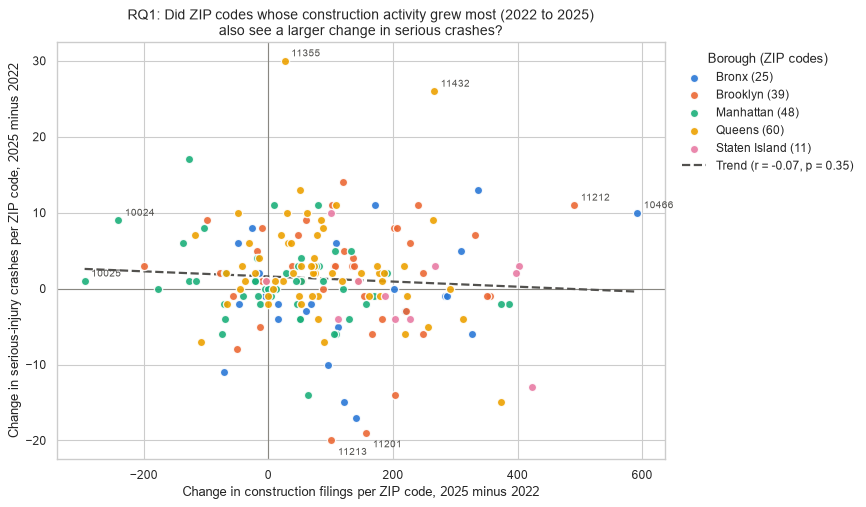

In [23]:
fig, ax = plt.subplots(figsize=(11, 6.5))

for boro in BOROUGHS:
    g = rq1[rq1["borough"] == boro]
    ax.scatter(g["filing_change"], g["crash_change"], s=55, color=BOROUGH_COLORS[boro],
               edgecolor="white", linewidth=1.2, alpha=0.9, label=f"{boro.title()} ({len(g)})", zorder=3)

# Least-squares trend line over all ZIP codes
slope, intercept = np.polyfit(rq1["filing_change"], rq1["crash_change"], 1)
xs = np.linspace(rq1["filing_change"].min(), rq1["filing_change"].max(), 100)
ax.plot(xs, slope * xs + intercept, color="#52514e", linewidth=2, linestyle="--", zorder=2,
        label=f"Trend (r = {r:.2f}, p = {p_r:.2f})")

ax.axhline(0, color="#898781", linewidth=1, zorder=1)
ax.axvline(0, color="#898781", linewidth=1, zorder=1)

# Label only the most extreme ZIP codes on each axis
to_label = set(rq1["filing_change"].nlargest(2).index) | set(rq1["filing_change"].nsmallest(2).index) \
         | set(rq1["crash_change"].nlargest(2).index) | set(rq1["crash_change"].nsmallest(2).index)
for z in to_label:
    ax.annotate(z, (rq1.loc[z, "filing_change"], rq1.loc[z, "crash_change"]),
                xytext=(6, -13 if rq1.loc[z, "crash_change"] < 0 else 4), textcoords="offset points",
                fontsize=9, color="#52514e")

ax.set_title("RQ1: Did ZIP codes whose construction activity grew most (2022 to 2025)\n"
             "also see a larger change in serious crashes?", fontsize=13)
ax.set_xlabel("Change in construction filings per ZIP code, 2025 minus 2022")
ax.set_ylabel("Change in serious-injury crashes per ZIP code, 2025 minus 2022")
ax.legend(title="Borough (ZIP codes)", frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

**RQ1 interpretation.** The calculated finding below states the direction and strength of the association between each ZIP code's 2022-to-2025 change in filings and its change in serious crashes. The p-values assume independent ZIP codes; neighbouring ZIPs are not independent, and this is one of several exploratory comparisons, so they are only a rough guide.

The result cannot separate construction from changes in population, traffic, reporting or anything else. Four years and two endpoints are limited, and regression to the mean affects change scores (ZIP codes with many crashes in 2022 tend to fall back). No claim that construction is safe or harmful is warranted.

In [24]:
def describe_strength(value):
    size = abs(value)
    if size < 0.1:
        return "no meaningful"
    label = "a weak" if size < 0.3 else "a moderate" if size < 0.5 else "a strong"
    return f"{label} {'positive' if value > 0 else 'negative'}"

display(Markdown(
    f"**Calculated RQ1 finding:** across {len(rq1):,} ZIP codes, the change in filings from 2022 to 2025 shows "
    f"**{describe_strength(r)} linear relationship** with the change in serious crashes "
    f"(Pearson r = {r:.2f}, p = {p_r:.2f}; Spearman rho = {rho:.2f}, p = {p_rho:.2f}). "
    "ZIP codes where construction grew most did not reliably see larger crash changes. "
    "This is a descriptive association, not a construction effect."
    if abs(r) < 0.1 else
    f"**Calculated RQ1 finding:** across {len(rq1):,} ZIP codes, the change in filings from 2022 to 2025 shows "
    f"**{describe_strength(r)} linear relationship** with the change in serious crashes "
    f"(Pearson r = {r:.2f}, p = {p_r:.2f}; Spearman rho = {rho:.2f}, p = {p_rho:.2f}). "
    "This is a descriptive association, not a construction effect."))

**Calculated RQ1 finding:** across 183 ZIP codes, the change in filings from 2022 to 2025 shows **no meaningful linear relationship** with the change in serious crashes (Pearson r = -0.07, p = 0.35; Spearman rho = -0.08, p = 0.26). ZIP codes where construction grew most did not reliably see larger crash changes. This is a descriptive association, not a construction effect.

### 8.2 Research question 2

> **RQ2: Is a ZIP code's construction activity in one year associated with its serious crashes in the following year?**

If construction affected road safety (e.g. through work zones, trucks, or blocked sidewalks), the effect might show up with a delay, as projects move from filing to work on site. RQ1 compared only the two end years; RQ2 uses **every pair of consecutive years** (2022→2023, 2023→2024, 2024→2025).

- **Rows used:** ZIP-years with housing data and a known next year, in ZIP codes that appear in the crash file (2025 has no next year). The count is printed below.
- **Two views of the same data:**
  1. **Between ZIP codes:** do ZIP-years with more filings have more crashes the next year? This is the naive comparison, and it mixes in ZIP size.
  2. **Within each ZIP code:** in years when a ZIP had *more filings than its own average*, did it have *more crashes than its own average* the next year? Subtracting each ZIP's own average removes size, density and every other fixed difference between ZIP codes.
- **Extra check:** a small regression of next-year crashes on this year's filings *and* this year's crashes, to see whether filings add anything once we know a ZIP's current crash level.

In [25]:
rq2 = integrated[integrated["has_housing_data"] & integrated["crashes_next_year"].notna()
                 & integrated["zip_code"].isin(crash_zips)].copy()
rq2["filing_count"] = rq2["filing_count"].astype(float)
rq2["crashes_next_year"] = rq2["crashes_next_year"].astype(float)
print(f"Rows used: {len(rq2)} ZIP-years ({rq2['zip_code'].nunique()} ZIP codes x years {sorted(rq2['year'].unique().tolist())})\n")

# View 1: between ZIP codes
r_b, p_b = stats.pearsonr(rq2["filing_count"], rq2["crashes_next_year"])
rho_b, p_rho_b = stats.spearmanr(rq2["filing_count"], rq2["crashes_next_year"])
print(f"Pooled ZIP-years (descriptive): Pearson r = {r_b:.2f}, Spearman rho = {rho_b:.2f}")

# View 2: within each ZIP code (deviation from the ZIP's own 2022-2024 average)
rq2["filing_dev"] = rq2["filing_count"] - rq2.groupby("zip_code")["filing_count"].transform("mean")
rq2["crash_next_dev"] = rq2["crashes_next_year"] - rq2.groupby("zip_code")["crashes_next_year"].transform("mean")
r_w, p_w = stats.pearsonr(rq2["filing_dev"], rq2["crash_next_dev"])
print(f"Within-ZIP deviations (descriptive): Pearson r = {r_w:.2f}; repeated ZIP-years, no independence-based p-value")

# Extra check: next-year crashes ~ this year's filings + this year's crashes (ordinary least squares)
X = np.column_stack([np.ones(len(rq2)), rq2["filing_count"], rq2["crash_count"]])
coef, *_ = np.linalg.lstsq(X, rq2["crashes_next_year"], rcond=None)
print(f"\nRegression: next-year crashes = {coef[0]:.2f} + {coef[1]:.4f} x filings + {coef[2]:.2f} x this year's crashes")
print(f"-> 100 extra filings go with {coef[1] * 100:+.2f} serious crashes next year, once this year's crashes are known")

# Quartiles describe volume groups, not treatment groups.
rq2["filing_quartile"] = pd.qcut(rq2["filing_count"], 4, labels=["Q1 (fewest)", "Q2", "Q3", "Q4 (most)"])
rq2["dev_quartile"] = pd.qcut(rq2["filing_dev"], 4, labels=["Much below\nown average", "Below", "Above", "Much above\nown average"])
summary_between = rq2.groupby("filing_quartile", observed=True).agg(
    filings_range=("filing_count", lambda s: f"{s.min():.0f}-{s.max():.0f}"),
    median_crashes_next_year=("crashes_next_year", "median"), rows=("zip_code", "size"))
summary_within = rq2.groupby("dev_quartile", observed=True).agg(
    median_crash_next_dev=("crash_next_dev", "median"), mean_crash_next_dev=("crash_next_dev", "mean"),
    rows=("zip_code", "size")).round(2)
display(summary_between)
display(summary_within)

Rows used: 550 ZIP-years (184 ZIP codes x years [2022, 2023, 2024])

Pooled ZIP-years (descriptive): Pearson r = 0.40, Spearman rho = 0.61
Within-ZIP deviations (descriptive): Pearson r = 0.06; repeated ZIP-years, no independence-based p-value

Regression: next-year crashes = 1.87 + 0.0014 x filings + 0.82 x this year's crashes
-> 100 extra filings go with +0.14 serious crashes next year, once this year's crashes are known


,filings_range,median_crashes_next_year,rows
filing_quartile,,,
Q1 (fewest),1-326,4.0,138
Q2,327-606,12.0,137
Q3,610-1009,19.0,137
Q4 (most),1013-3369,19.0,138


,median_crash_next_dev,mean_crash_next_dev,rows
dev_quartile,,,
Much below\nown average,-0.67,-0.64,138
Below,0.33,0.54,140
Above,-0.33,-0.31,134
Much above\nown average,0.33,0.40,138


Panel A compares ZIP-years with each other, which mixes in ZIP size. Panel B compares each ZIP code with its own average, which removes fixed size differences. A real lagged link would show boxes rising from left to right in **both** panels.

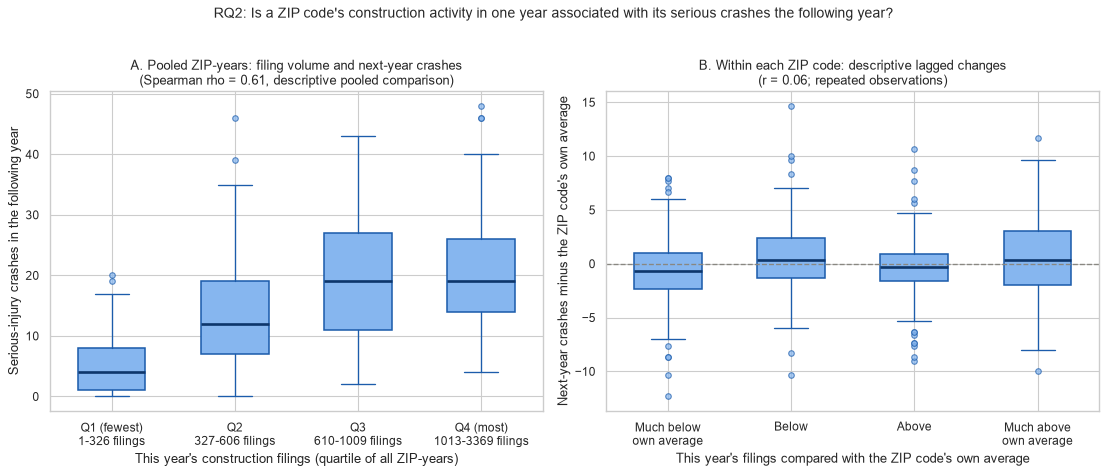

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.8))
box_style = dict(patch_artist=True, widths=0.55, showfliers=True,
                 boxprops=dict(facecolor="#86b6ef", edgecolor="#1c5cab", linewidth=1.4),
                 medianprops=dict(color="#0d366b", linewidth=2.4),
                 whiskerprops=dict(color="#1c5cab", linewidth=1.2), capprops=dict(color="#1c5cab", linewidth=1.2),
                 flierprops=dict(marker="o", markersize=5, markerfacecolor="#86b6ef", markeredgecolor="#1c5cab", alpha=0.7))

# Panel A: between ZIP codes
cats_a = rq2["filing_quartile"].cat.categories
axes[0].boxplot([rq2.loc[rq2["filing_quartile"] == c, "crashes_next_year"] for c in cats_a], **box_style)
axes[0].set_xticks(range(1, 5), [f"{c}\n{summary_between.loc[c, 'filings_range']} filings" for c in cats_a])
axes[0].set_title(f"A. Pooled ZIP-years: filing volume and next-year crashes\n"
                  f"(Spearman rho = {rho_b:.2f}, descriptive pooled comparison)", fontsize=11.5)
axes[0].set_xlabel("This year's construction filings (quartile of all ZIP-years)")
axes[0].set_ylabel("Serious-injury crashes in the following year")

# Panel B: within each ZIP code
cats_b = rq2["dev_quartile"].cat.categories
axes[1].boxplot([rq2.loc[rq2["dev_quartile"] == c, "crash_next_dev"] for c in cats_b], **box_style)
axes[1].axhline(0, color="#898781", linewidth=1.2, linestyle="--")
axes[1].set_xticks(range(1, 5), cats_b)
axes[1].set_title(f"B. Within each ZIP code: descriptive lagged changes\n"
                  f"(r = {r_w:.2f}; repeated observations)", fontsize=11.5)
axes[1].set_xlabel("This year's filings compared with the ZIP code's own average")
axes[1].set_ylabel("Next-year crashes minus the ZIP code's own average")

fig.suptitle("RQ2: Is a ZIP code's construction activity in one year associated with its serious crashes the following year?",
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

**RQ2 interpretation:** compare the pooled between-place correlation to the within-ZIP deviations printed above. A pooled association does not establish a within-place change. The rows contain repeated ZIPs; ordinary independence-based p-values do **not** account for clustering, so they are not reported for this repeated-observation analysis. The regression is descriptive, not a causal model.

Potential confounders include traffic volume, population, density and land use, none of which are measured here. Three consecutive-year pairs per ZIP are too few to rule out small effects or alternative lags. Filing dates are not dates of work on site. Official postcode reduces—but does not eliminate—geographic uncertainty.

In [27]:
if r_b >= 0.3 and abs(r_w) < 0.1:
    reading = ("The between-ZIP association largely disappears within ZIP codes: busier ZIP codes have both more "
               "filings and more crashes, but a ZIP's above-average filing years are not followed by above-average "
               "crash years. This points to ZIP size and activity level, not a year-to-year construction link.")
else:
    reading = "Compare the two views before drawing any conclusion; neither is a causal estimate."
display(Markdown(
    f"**Calculated RQ2 finding:** {len(rq2):,} ZIP-years in {rq2['zip_code'].nunique()} ZIP codes. "
    f"Between ZIP codes: Pearson r = **{r_b:.2f}**, Spearman rho = **{rho_b:.2f}**. "
    f"Within each ZIP code: r = **{r_w:.2f}**. Once this year's crashes are known, 100 extra filings go with "
    f"**{coef[1] * 100:+.2f}** serious crashes the next year. {reading} "
    "Repeated observations and unmeasured exposure prevent causal interpretation."))

**Calculated RQ2 finding:** 550 ZIP-years in 184 ZIP codes. Between ZIP codes: Pearson r = **0.40**, Spearman rho = **0.61**. Within each ZIP code: r = **0.06**. Once this year's crashes are known, 100 extra filings go with **+0.14** serious crashes the next year. The between-ZIP association largely disappears within ZIP codes: busier ZIP codes have both more filings and more crashes, but a ZIP's above-average filing years are not followed by above-average crash years. This points to ZIP size and activity level, not a year-to-year construction link. Repeated observations and unmeasured exposure prevent causal interpretation.

## 9. Prompts

An AI assistant (Claude) was used to help write and debug the code in this notebook; every result was run and reviewed by the author (Aya Sweed, Member 3). The same list is kept in `docs/prompts.md`. Each entry gives the prompt and, in brackets, what was checked.

These record the original development pass and its old snapshot counts, **not the current regenerated results**. The correction request and approved methodology are in `docs/prompts.md`.

1. Check whether the housing data Member 1 used is the real H5 table, and download the full dataset for 2022-2025. (found the local snapshot was an 18,500-row sample with columns that don't exist in H5; wrote `members/member3_integration/fetch_h5_data.py`, which downloaded 598,706 rows)
2. Re-run Member 1's housing notebook on the real data and fix any errors. (fixed the import path for `assign_zip_from_sirta`, a pandas 3 dtype check, and domain checks 4a/4b, which were dropping 316,671 filings with blank height or units; checked that only 633 rows are now removed and that `housing_clean.csv` has 736 rows = 184 ZIPs x 4 years)
3. What exactly should Member 1 fix after the regeneration? (list: dwelling units double-counted across filings of the same job, an uncaught 111,111,111 typo, markdown cells written about the old sample)
4. Draft a task-based plan for my integration work that I can approve step by step. (tasks: key checks, outer merge, post-integration cleaning, derived columns, validation/export, 2 research questions)
5. Create the integration notebook with its goal, inputs/outputs, and a markdown section explaining why we join on ZIP code x year and which alternatives we rejected. (reviewed the reasoning: record level not allowed, borough x year only 20 rows, spatial join and monthly grain considered; noted the nearest-crash ZIP assignment as a limitation)
6. Load both cleaned files and check the join keys before merging: 5-digit text ZIP codes, integer years 2022-2025, unique (zip_code, year) pairs, uppercase boroughs. (all checks passed: housing 736 rows / 184 ZIPs, transport 703 rows / 185 ZIPs; found 4 columns present in both files to resolve after the merge)
7. Merge the two files with an outer join on zip_code + year, chart how many ZIP-years matched / are housing-only / transport-only, and list the one-sided ZIP codes. (738 rows: 701 matched, 35 housing-only, 2 transport-only; checked that every housing-only ZIP has crashes in other years and that the transport-only ZIP 10282 has no filings because of nearest-crash ZIP assignment)
8. Do the post-integration cleaning: resolve the duplicated columns, fill the missing values created by the join, add source flags, and fix data types. For ZIP 10282 (no housing row), use a flag instead of filling filing_count with 0. (0 borough conflicts; replaced 4 coordinate columns with one centroid per ZIP; crash counts set to 0 on 35 housing-only rows but crash rates left blank; added has_housing_data / has_crash_data; checked the before/after missing-value table)
9. Add derived columns: crashes per 100 filings, year-over-year change in filings and crashes, next-year crashes, and severe injuries per 1,000 units (marked provisional until Member 1's unit fix). (year links matched on year +/- 1, not row order; checked each column is blank only where it should be, e.g. crashes_next_year blank for 2025; verified ZIP 11207 by hand)
10. Validate the integrated table and export integrated_dataset.csv: row count, unique keys, totals matching the source files, data contract, plus a column summary for Members 4 and 5. (738 rows x 34 columns; all filing and crash totals equal the source files; re-read the saved CSV to confirm ZIP codes stay 5-digit text)
11. Research question 1: did ZIP codes whose construction activity grew most between 2022 and 2025 also see a larger change in serious crashes? Make a scatter chart with title, axis labels and trend line. (184 ZIP codes; no relationship, Pearson r = -0.07, p = 0.37; checked regression to the mean and per-borough results; wrote limitations, no causal claims)
12. Research question 2: is a ZIP code's construction activity in one year associated with its serious crashes the following year? Compare between ZIP codes and within each ZIP code, with a two-panel box-plot chart. (552 ZIP-years; between ZIP codes Spearman rho = 0.63, within ZIP codes r = 0.04, p = 0.37; regression: 100 extra filings go with +0.14 crashes next year; interpreted as a ZIP-size effect, not a construction effect)
13. Review my prompt log, add a prompts section to the notebook, and draft my 2-3 line contribution entry for the README. (checked the wording and added my name)
14. Check Pierre's correction PRs and finish my integration fixes now that Member 1's work is merged: update the notebook text to the regenerated data, remove the old provisional wording, and keep ZIP codes that never appear in the crash file out of the research questions. (checked against the live API that H5 does have a building postcode; replaced stale hard-coded counts and placeholder markdown; re-ran the notebook, all key and total checks pass)